# SEI Research

Исследование Signed Entropy Integral (SEI) для обнаружения ошибочных меток.

Основная часть экспериментов проводится на Fashion-MNIST с искусственным шумом. Дополнительная проверка — на CIFAR-10 с чистыми исходными метками и независимо сгенерированным симметричным шумом. CIFAR-10N в этом варианте ноутбука не используется.


## Импорты и настройки

In [21]:
import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import torch
from torch.utils.data import TensorDataset, DataLoader
from torchvision import datasets

from sklearn.model_selection import StratifiedKFold
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (
    average_precision_score, roc_auc_score, accuracy_score,
    precision_recall_curve, f1_score,
)
from cleanlab.rank import get_label_quality_scores

# Импорты из src
PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / "src").is_dir() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent

if not (PROJECT_ROOT / "src").is_dir():
    raise FileNotFoundError("Не найдена src")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.models import SimpleCNN, FashionCNN, count_trainable_parameters
from src.data import load_small_dataset
from src.training import train_one_epoch, predict, measure_cnn_quality, train_and_measure
from src.utils import set_seed, get_device

#константы
SEED = 123
DATASET_NAME = "FashionMNIST"  # MNIST или FashionMNIST
TRAIN_LIMIT = 50000
TEST_LIMIT = None
NOISE_TYPE = "symmetric" #"symmetric"  #"class_dependent", "instance_dependent"
NOISE_RATE = 0.10       #доля меток, которые испортим
FOLDS = 3              #для кросс-валидации
ENSEMBLE_SIZE = 3
EPOCHS = 50
OOF_EPOCHS = 50
BATCH_SIZE = 128
K_NEIGHBORS = 10
CNN_QUALITY_EPOCHS = 100
CNN_QUALITY_SEEDS = [SEED]
CLEANING_REPEAT_SEEDS = [SEED]
CLEANING_FINAL_EPOCHS = 50

# Переключатели oof методов(false, поскольку сейчас фокус на энтропию) 
RUN_CLEANLAB_8_4 = True             # Cleanlab в 8.4 по out-of-fold вероятностям
RUN_LEGACY_CLEANING = False         # этапы 7 и 9; требуют OOF-результатов
RUN_CLASSIFIER_COMPARISONS = False  # этап 1.1 и этап 10; отдельные долгие обучения CNN
# CIFAR-10 запускается отдельным экспериментом в этапе 8.6.
# Используются чистые исходные метки CIFAR-10; шум создаётся искусственно.

REQUIRE_CUDA = True
DEVICE = get_device(require_cuda=REQUIRE_CUDA)
if DEVICE.type == "cuda":
    print("Устройство:", torch.cuda.get_device_name(0))
    print("Версия CUDA в PyTorch:", torch.version.cuda)
else:
    print("Устройство:", DEVICE)

DATA_ROOT = PROJECT_ROOT / "data"
OUTPUT_DIR = PROJECT_ROOT / "results_vkr"
DATA_ROOT.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

set_seed()

Устройство: NVIDIA GeForce RTX 3060 Laptop GPU
Версия CUDA в PyTorch: 13.2


## Загрузка Fashion-MNIST / MNIST

In [2]:
X_train, y_true, X_test, y_test = load_small_dataset(
    DATASET_NAME, TRAIN_LIMIT, TEST_LIMIT, data_root=DATA_ROOT, seed=SEED
)
NUM_CLASSES = 10
print("Датасет:", DATASET_NAME)
print("Размер обучающей выборки:", len(y_true))
print("Размер тестовой выборки:", len(y_test))


Датасет: FashionMNIST
Размер обучающей выборки: 50000
Размер тестовой выборки: 10000


## Генерация искусственного шума для SEI

In [22]:
#ИСКУССТВЕННЫЙ ШУМ
def make_noisy_labels(X, y, noise_type, noise_rate, seed=SEED):
    """Меняет заданную долю меток и возвращает их плюс маску ошибок."""
    rng = np.random.default_rng(seed)
    y_original = y.cpu().numpy().copy()
    y_noisy = y_original.copy()
    n_classes = len(np.unique(y_original))
    n_errors = int(round(len(y_original) * noise_rate))

    if noise_type == "instance_dependent":
        variation = X.flatten(1).std(dim=1).cpu().numpy()
        weights = 1.0 / (variation + 0.05)
        weights = weights / weights.sum()
        bad_ids = rng.choice(len(y_original), size=n_errors, replace=False, p=weights)
    else:
        bad_ids = rng.choice(len(y_original), size=n_errors, replace=False)

    if noise_type == "class_dependent":
        y_noisy[bad_ids] = (y_original[bad_ids] + 1) % n_classes

    elif noise_type in ("symmetric", "instance_dependent"):
        new_labels = rng.integers(0, n_classes, size=n_errors)
        same = new_labels == y_original[bad_ids]
        while same.any():
            new_labels[same] = rng.integers(0, n_classes, size=same.sum())
            same = new_labels == y_original[bad_ids]
        y_noisy[bad_ids] = new_labels

    else:
        raise ValueError("Неизвестный тип шума")

    noise_mask = y_noisy != y_original
    return torch.tensor(y_noisy, dtype=torch.long), noise_mask


y_noisy, noise_mask = make_noisy_labels(X_train, y_true, NOISE_TYPE, NOISE_RATE)
print("Тип шума:", NOISE_TYPE)
print("Заданный уровень шума:", NOISE_RATE)
print("Фактически испорчено меток:", int(noise_mask.sum()), "из", len(noise_mask))

Тип шума: symmetric
Заданный уровень шума: 0.1
Фактически испорчено меток: 5000 из 50000


## Вспомогательная функция оценки рейтинга подозрительности

In [4]:
def evaluate_score(name, score, bad_mask):
    bad_mask = np.asarray(bad_mask).astype(int)
    score = np.asarray(score)
    k = max(1, int(bad_mask.sum()))  # K берётся из числа реальных ошибок только для оценки
    top_ids = np.argsort(score)[::-1][:k]
    return {
        "Метод": name,
        "Precision@K": bad_mask[top_ids].mean(),
        "Average Precision": average_precision_score(bad_mask, score), 
        "ROC-AUC": roc_auc_score(bad_mask, score) if len(np.unique(bad_mask)) > 1 else np.nan,
        }

'''
 #Чем выше Precision@K, тем меньше правильных меток ошибочно отнесли к подозрительным при таком размере списка
 #Высокий AP = испорченные метки в целом оказываются ближе к началу списка подозрительности
 #ROC-AUC способность рейтинга отделять испорченные метки от правильных при рассмотрении разных порогов
'''

'\n #Чем выше Precision@K, тем меньше правильных меток ошибочно отнесли к подозрительным при таком размере списка\n #Высокий AP = испорченные метки в целом оказываются ближе к началу списка подозрительности\n #ROC-AUC способность рейтинга отделять испорченные метки от правильных при рассмотрении разных порогов\n'

## Проверка на CIFAR-10 с искусственным шумом

Вместо CIFAR-10N используется стандартный CIFAR-10 с исходными чистыми метками. Искусственный симметричный шум независимо создаётся для обучающей, валидационной и тестовой частей. Поэтому истинная маска ошибок известна и может использоваться для выбора порога по F1 на валидации и последующей независимой оценки на тесте.


### Параметры эксперимента CIFAR-10

In [23]:
# Отдельный контролируемый эксперимент на CIFAR-10
RUN_SEI_CIFAR10 = True

# CIFAR-10 содержит 50 000 обучающих и 10 000 тестовых изображений.
# 45 000 изображений идут на обучение, 5 000 - на подбор tau и F1-порога
CIFAR10_TRAIN_LIMIT = 45000
CIFAR10_VAL_LIMIT = 5000
CIFAR10_TEST_LIMIT = None  # None - использовать весь тест CIFAR-10

CIFAR10_NOISE_TYPE = "symmetric"
CIFAR10_NOISE_RATE = 0.10
CIFAR10_RUN_CLEAN_CNN_BASELINE = True
CIFAR10_SEED_OFFSET = 5000


In [6]:
def load_cifar10_splits(
    data_root=DATA_ROOT,
    train_limit=CIFAR10_TRAIN_LIMIT,
    val_limit=CIFAR10_VAL_LIMIT,
    test_limit=CIFAR10_TEST_LIMIT,
    seed=SEED,
):
    """Загрузка локального CIFAR-10 и деление train на train/val"""
    data_root = str(data_root)
    try:
        train_ds = datasets.CIFAR10(
            root=data_root, train=True, download=False
        )
        test_ds = datasets.CIFAR10(
            root=data_root, train=False, download=False
        )
    except (RuntimeError, FileNotFoundError) as exc:
        expected = Path(data_root) / "cifar-10-batches-py"
        raise FileNotFoundError(
            "Не удалось найти локальный CIFAR-10"
        ) from exc

    n_train = len(train_ds.targets)
    if train_limit <= 0 or val_limit <= 0:
        raise ValueError("train_limit и val_limit должны быть положительными")
    if train_limit + val_limit > n_train:
        raise ValueError(
            f"train_limit + val_limit = {train_limit + val_limit}, "
            f"но CIFAR-10 содержит только {n_train} обучающих изображений"
        )

    generator = torch.Generator().manual_seed(seed)
    perm = torch.randperm(n_train, generator=generator)
    train_ids = perm[:train_limit]
    val_ids = perm[train_limit:train_limit + val_limit]

    def to_tensors(dataset, ids):
        images = torch.as_tensor(np.asarray(dataset.data)[ids.numpy()].copy())
        images = images.permute(0, 3, 1, 2).contiguous().float() / 255.0
        labels = torch.as_tensor(
            np.asarray(dataset.targets)[ids.numpy()].copy(),
            dtype=torch.long,
        )
        return images, labels

    X_train, y_train = to_tensors(train_ds, train_ids)
    X_val, y_val = to_tensors(train_ds, val_ids)

    if test_limit is None or test_limit >= len(test_ds.targets):
        test_ids = torch.arange(len(test_ds.targets))
    else:
        if test_limit <= 0:
            raise ValueError("test_limit должен быть положительным или None")
        test_generator = torch.Generator().manual_seed(seed + 1)
        test_ids = torch.randperm(
            len(test_ds.targets), generator=test_generator
        )[:test_limit]

    X_test, y_test = to_tensors(test_ds, test_ids)

    return {
        "X_train": X_train,
        "y_train_clean": y_train,
        "X_val": X_val,
        "y_val_clean": y_val,
        "X_test": X_test,
        "y_test_clean": y_test,
    }


print("Загрузчик CIFAR-10 готов. Данные будут прочитаны из:", DATA_ROOT)


Загрузчик CIFAR-10 готов. Данные будут прочитаны из: c:\Users\aptem\OneDrive\Desktop\политех\лабы\ВКР\data


# **8 этап** на основе статьи из arxiv
## реализация знаковой энтропии

In [24]:
# 8.1 обучение траекторий и параметры SEI
SEI_EPOCHS = 100
CIFAR10_EPOCHS = SEI_EPOCHS  # CIFAR-10 обучается столько же эпох, сколько основной SEI
SEI_LR = 1e-3

# Температуры проверяются по независимой валидационной выборке.
TAU_GRID = sorted(set(
    [65536.0, 32768.0, 16384.0, 8192.0, 4096.0, 2048.0, 1024.0, 512.0, 256.0, 128.0, 64.0, 32.0, 16.0, 8.0, 4.0]
    + [2.0 / 2**i for i in range(8)]
))

VAL_NOISE_RATE = 0.10
VAL_LIMIT = 3000
TAU_TUNING_SEEDS = [SEED]
EVAL_NOISE_TYPES = [NOISE_TYPE]
EVAL_NOISE_RATES = [NOISE_RATE]
EVAL_SEEDS = [SEED]
EPS = 1e-12

# Auxiliary Class использует tau, подобранные в текущем запуске этапа 8.3.
RUN_AUXILIARY_CLASS = True
AUX_SAMPLE_MULTIPLIER = 1.0  # N_aux = N / (K + 1)
AUX_LOO_OPTIONS = [False, True]
AUX_SEED_OFFSET = 9000


@torch.no_grad()
def predict_logits(model, X, batch_size=BATCH_SIZE):
    """Возвращает логиты и features (fc1 + ReLU) для всех изображений."""
    model.eval()
    all_logits, all_features = [], []

    for start in range(0, len(X), batch_size):
        batch = X[start:start + batch_size].to(
            DEVICE, non_blocking=(DEVICE.type == "cuda")
        )
        logits, features = model(batch, return_features=True)
        all_logits.append(logits.cpu().numpy())
        all_features.append(features.cpu().numpy())

    return np.vstack(all_logits), np.vstack(all_features)


def train_with_trajectory(
    X, y_obs, num_classes, epochs=SEI_EPOCHS, lr=SEI_LR,
    seed=SEED, eval_X=None
):
    """Обучает SimpleCNN и сохраняет logits/features после каждой эпохи.

    Если eval_X задан, траектории сохраняются для eval_X, а также отдельно
    для обучающей выборки в reference_logits/reference_features.
    """
    set_seed(seed)
    model = SimpleCNN(in_channels=X.shape[1], num_classes=num_classes).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loader = DataLoader(
        TensorDataset(X, y_obs),
        batch_size=BATCH_SIZE,
        shuffle=True,
        pin_memory=(DEVICE.type == "cuda"),
    )

    target_X = X if eval_X is None else eval_X
    logits_hist, feats_hist = [], []
    reference_logits_hist, reference_feats_hist = [], []

    for epoch in range(epochs):
        train_one_epoch(model, loader, optimizer)
        logits, feats = predict_logits(model, target_X)
        logits_hist.append(logits.astype(np.float32))
        feats_hist.append(feats.astype(np.float32))

        if eval_X is not None:
            reference_logits, reference_feats = predict_logits(model, X)
            reference_logits_hist.append(reference_logits.astype(np.float32))
            reference_feats_hist.append(reference_feats.astype(np.float32))

    result = {
        "logits": np.stack(logits_hist),
        "features": np.stack(feats_hist),
    }
    if eval_X is not None:
        result["reference_logits"] = np.stack(reference_logits_hist)
        result["reference_features"] = np.stack(reference_feats_hist)
    return result


# **Теория (формулы) logits, features и вычисление SEI в этом проекте**

## 1) логиты, признаки

**features** - промежуточное представление изображения после `fc1` и ReLU, его размерность: 64

$${h_e(x) = \operatorname{ReLU}(W_1^{(e)}q_e(x)+b_1^{(e)})}$$
где $q_e$ : 
$$q_e(x) = \operatorname{Flatten}(\operatorname{Conv}_{\theta_e}(x))$$

Последний полносвязный слой формирует:

$${z_e(x) = W_2^{(e)}h_e(x)+b_2^{(e)}}$$

Это **logits** - вектор из $K$ необработанных оценок классов после `fc2`, до Softmax, $K=10$

$e$ - эпоха обучения, для каждого изображения сохраняются `features` и `logits` после каждой эпохи.

---

## 2) Softmax от logits

$$P_{i,c}^{(e)} = \operatorname{Softmax}(z_i^{(e)})_c = \frac{\exp(z_{i,c}^{(e)})}{\sum_{j=1}^{K}\exp(z_{i,j}^{(e)})}$$

Здесь нет прототипов, а параметр `tau` = 1.
Затем по $P$ вычисляется SEI по формулам ниже.

**пунктирная линия 0.7 на графике AUPRC:** при `seed=42` и симметричном шуме 20% на валидации получено `AUPRC = 0.697` - результат контрольного варианта `SEI (softmax logits)`, измеренный на валидации. Линия - горизонтальный baseline для сравнения с прототипными вариантами


## 3. Прототипы для features или logits

В обоих вариантах отличается только $v_i^{(e)}$:

* для `features`: $v_i^{(e)} = h_e(x_i)$;
* для `logits`: $v_i^{(e)} = z_e(x_i)$.

Для каждого класса $c$ на каждой эпохе вычисляется средний вектор по изображениям, которым в используемой разметке присвоен этот класс:

$${\mu_c^{(e)} = \frac{1}{n_c}\sum_{i:y_i=c}v_i^{(e)}}$$

Здесь $y_i$ - текущая метка обучающего изображения, а $n_c$ - число изображений с этой меткой

Перед сравнением векторы нормируются:

$$\widehat v_i^{(e)} = \frac{v_i^{(e)}}{\Vert{}v_i^{(e)}\Vert{}_2+\varepsilon}, \qquad \widehat\mu_c^{(e)} = \frac{\mu_c^{(e)}}{\Vert{}\mu_c^{(e)}\Vert{}_2+\varepsilon}$$
Здесь эпсилон используются для избежания деления на 0

Косинусное сходство изображения с каждым прототипом:

$${s_{i,c}^{(e)} = \widehat v_i^{(e)}\cdot\widehat\mu_c^{(e)}}$$

Сходства превращаются в вероятности Softmax с параметром $\tau$:

$${P_{i,c}^{(e)} = \frac{\exp(s_{i,c}^{(e)}/\tau)}{\sum_{j=1}^{K}\exp(s_{i,j}^{(e)}/\tau)}}$$


---

## 4) Энтропия

Энтропия распределения вероятностей изображения на эпохе $e$:

$${H_i^{(e)} = -\sum_{c=1}^{K}P_{i,c}^{(e)}\ln(P_{i,c}^{(e)}+\varepsilon)}$$



$$SE_i^{(e)} = \begin{cases} +H_i^{(e)}, & \arg\max_c P_{i,c}^{(e)} = y_i, \\ -H_i^{(e)}, & \arg\max_c P_{i,c}^{(e)} \neq y_i. \end{cases}$$


$${SEI_i = \sum_{e=1}^{E}SE_i^{(e)}}$$

рейтинг подозрительности имеет противоположный знак:

$${\operatorname{Score}_i = -SEI_i}$$

Поэтому большие значения `Score` означают более подозрительную метку

---

## 5) Другие варианты

* **SEI (softmax logits):** обычный Softmax от logits без прототипов; знаковая энтропия суммируется по всем эпохам
* **SEI прототипы [logits]:** прототипы строятся в пространстве logits, затем косинусное сходство, Softmax с $\tau$ и SEI
* **SEI прототипы [features]:** то же самое, но прототипы строятся в пространстве features
* **SE@last:** используется знаковая энтропия только последней эпохи.
* **SE@middle:** используется знаковая энтропия средней эпохи
* **EI без знака:** суммируется обычная энтропия без проверки совпадения предсказания с меткой.


In [25]:
# 8.2 — вычисление вероятностей и оценок SEI
def softmax_np(z, axis=-1):
    z = z - z.max(axis=axis, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=axis, keepdims=True)


def l2_normalize_rows(v, eps=EPS):
    """L2-нормирует каждый вектор по последней оси."""
    v = np.asarray(v, dtype=np.float32)
    return v / (np.linalg.norm(v, axis=-1, keepdims=True) + eps)


def entropy(P):
    return -(P * np.log(P + EPS)).sum(axis=-1)


def signed_entropy(P, y):
    H = entropy(P)
    agree = P.argmax(axis=-1) == y[None, :]
    return np.where(agree, H, -H)


def sei_value(P, y):
    return signed_entropy(P, y).sum(axis=0)


def sei_score(P, y):
    return -sei_value(P, y)


def ei_score(P, y):
    return entropy(P).sum(axis=0)


def se_last_score(P, y):
    return -signed_entropy(P, y)[-1]


def se_middle_score(P, y):
    return -signed_entropy(P, y)[P.shape[0] // 2]


def prototype_probs(V, y, num_classes, tau, loo=False):
    """Прототипы по формуле преподавателя.

    На каждой эпохе сначала L2-нормируются индивидуальные эмбеддинги,
    затем усредняются нормированные векторы класса, после чего
    нормируется сам прототип.
    """
    V = np.asarray(V, dtype=np.float32)
    y = np.asarray(y, dtype=int)
    epochs, n_samples, _ = V.shape

    if len(y) != n_samples:
        raise ValueError("Число меток не совпадает с числом эмбеддингов")
    if tau <= 0:
        raise ValueError("tau должен быть положительным")

    onehot = np.eye(num_classes, dtype=np.float32)[y]
    counts = onehot.sum(axis=0)
    P = np.empty((epochs, n_samples, num_classes), dtype=np.float32)
    idx = np.arange(n_samples)

    for e in range(epochs):
        # 1. Нормируем каждый эмбеддинг отдельно.
        Vn = l2_normalize_rows(V[e])

        # 2. Усредняем уже нормированные эмбеддинги по классам.
        sums = onehot.T @ Vn
        means = sums / np.maximum(counts, 1.0)[:, None]

        # 3. Нормируем средние векторы — получаем прототипы.
        Tn = l2_normalize_rows(means)
        similarities = Vn @ Tn.T

        if loo:
            own_counts = counts[y]
            valid = own_counts > 1
            if np.any(valid):
                means_loo = (
                    sums[y[valid]] - Vn[valid]
                ) / (own_counts[valid, None] - 1.0)
                prototypes_loo = l2_normalize_rows(means_loo)
                similarities[idx[valid], y[valid]] = (
                    Vn[valid] * prototypes_loo
                ).sum(axis=1)

        P[e] = softmax_np(similarities / tau)

    return P


def compute_sei_scores(traj, y, best_tau):
    K = traj["logits"].shape[-1]
    P_soft = softmax_np(traj["logits"])

    out = {
        "SEI (softmax логитов)": sei_score(P_soft, y),
        "EI без знака (softmax)": ei_score(P_soft, y),
        "SE@last (softmax)": se_last_score(P_soft, y),
        "SE@middle (softmax)": se_middle_score(P_soft, y),
    }

    for (emb, loo), tau in best_tau.items():
        P = prototype_probs(traj[emb], y, K, tau, loo)
        out[f"SEI прототипы [{emb}{', LOO' if loo else ''}]"] = sei_score(P, y)

    return out


def prototype_probs_external(
    V_query, V_reference, y_reference, num_classes, tau
):
    """Вероятности для query-объектов по прототипам reference-выборки.

    И query-векторы, и reference-векторы L2-нормируются до построения
    прототипов. Прототипы вычисляются только по reference-объектам.
    """
    V_query = np.asarray(V_query, dtype=np.float32)
    V_reference = np.asarray(V_reference, dtype=np.float32)
    y_reference = np.asarray(y_reference, dtype=int)

    epochs, n_query, _ = V_query.shape
    if V_reference.shape[0] != epochs:
        raise ValueError("Число эпох query и reference не совпадает")
    if V_reference.shape[1] != len(y_reference):
        raise ValueError("Число reference-векторов не совпадает с числом меток")
    if tau <= 0:
        raise ValueError("tau должен быть положительным")

    onehot = np.eye(num_classes, dtype=np.float32)[y_reference]
    counts = onehot.sum(axis=0)
    probabilities = np.empty((epochs, n_query, num_classes), dtype=np.float32)

    for e in range(epochs):
        query_norm = l2_normalize_rows(V_query[e])
        reference_norm = l2_normalize_rows(V_reference[e])

        # Сначала нормированные reference-векторы усредняются по классам.
        means = (onehot.T @ reference_norm) / np.maximum(counts, 1.0)[:, None]
        prototypes = l2_normalize_rows(means)

        similarities = query_norm @ prototypes.T
        probabilities[e] = softmax_np(similarities / tau)

    return probabilities


In [9]:
# Auxiliary Class Threshold: прототипная адаптация для обычной CNN

def make_auxiliary_anchor_mask(
    n_samples, num_classes, seed=SEED, sample_multiplier=AUX_SAMPLE_MULTIPLIER
):
    """Случайно выбирает pseudo-anchor объекты для вспомогательного класса."""
    if n_samples < 2:
        raise ValueError("Для Auxiliary Class требуется минимум два обучающих объекта")
    if sample_multiplier <= 0:
        raise ValueError("sample_multiplier должен быть положительным")

    n_aux = int(round(n_samples / (num_classes + 1) * sample_multiplier))
    n_aux = min(max(n_aux, 2), n_samples - 1)

    rng = np.random.default_rng(seed)
    anchor_ids = rng.choice(n_samples, size=n_aux, replace=False)
    anchor_mask = np.zeros(n_samples, dtype=bool)
    anchor_mask[anchor_ids] = True
    return anchor_mask


def auxiliary_class_sei(V, y_observed, num_classes, tau, anchor_mask, loo=True):
    """SEI по K+1 прототипам с нормированием эмбеддингов до усреднения.

    CNN обучается на K исходных классах. Дополнительный класс существует
    только на этапе построения прототипов и расчёта вероятностей.
    """
    V = np.asarray(V, dtype=np.float32)
    y_observed = np.asarray(y_observed, dtype=int)
    anchor_mask = np.asarray(anchor_mask, dtype=bool)

    if V.ndim != 3:
        raise ValueError("V должен иметь форму (epochs, samples, dimensions)")
    epochs, n_samples, _ = V.shape
    if len(y_observed) != n_samples or len(anchor_mask) != n_samples:
        raise ValueError("Размеры V, y_observed и anchor_mask не совпадают")
    if not anchor_mask.any() or anchor_mask.all():
        raise ValueError("Auxiliary Class должен содержать от 1 до N-1 объектов")
    if not np.isfinite(tau) or tau <= 0:
        raise ValueError("tau должен быть положительным конечным числом")
    if np.any((y_observed < 0) | (y_observed >= num_classes)):
        raise ValueError("В y_observed обнаружены метки вне диапазона исходных классов")

    y_aux = y_observed.copy()
    y_aux[anchor_mask] = num_classes
    n_total_classes = num_classes + 1
    onehot = np.eye(n_total_classes, dtype=np.float32)[y_aux]
    counts = onehot.sum(axis=0)

    sei_values = np.zeros(n_samples, dtype=np.float64)
    sample_ids = np.arange(n_samples)

    for epoch in range(epochs):
        # 1. Нормируем каждый эмбеддинг до расчёта среднего.
        Vn = l2_normalize_rows(V[epoch])

        # 2. Строим суммы и средние векторов K+1 классов.
        sums = onehot.T @ Vn
        means = sums / np.maximum(counts, 1.0)[:, None]

        # 3. Нормируем каждый прототип.
        prototypes = l2_normalize_rows(means)
        similarities = Vn @ prototypes.T

        if loo:
            own_counts = counts[y_aux]
            valid = own_counts > 1
            if np.any(valid):
                means_loo = (
                    sums[y_aux[valid]] - Vn[valid]
                ) / (own_counts[valid, None] - 1.0)
                prototypes_loo = l2_normalize_rows(means_loo)
                similarities[sample_ids[valid], y_aux[valid]] = (
                    Vn[valid] * prototypes_loo
                ).sum(axis=1)

        probabilities = softmax_np(similarities / tau)
        sei_values += signed_entropy(probabilities[None, :, :], y_aux)[0]

    threshold_sei = float(np.mean(sei_values[anchor_mask]))
    predicted_bad = sei_values < threshold_sei

    return {
        "sei_values": sei_values,
        "suspicion_score": -sei_values,
        "aux_labels": y_aux,
        "anchor_mask": anchor_mask,
        "threshold_sei": threshold_sei,
        "threshold_score": -threshold_sei,
        "predicted_bad": predicted_bad,
        "n_aux": int(anchor_mask.sum()),
        "tau": float(tau),
        "loo": bool(loo),
    }


def evaluate_auxiliary_threshold(true_noise_mask, auxiliary_result):
    """Оценивает зафиксированный auxiliary-порог; маска используется только здесь."""
    y_true_bin = np.asarray(true_noise_mask, dtype=bool)
    y_pred_bin = np.asarray(auxiliary_result["predicted_bad"], dtype=bool)
    if y_true_bin.shape != y_pred_bin.shape:
        raise ValueError("Маска истинных ошибок и предсказания должны совпадать по размеру")

    tp = int(np.sum(y_true_bin & y_pred_bin))
    fp = int(np.sum(~y_true_bin & y_pred_bin))
    fn = int(np.sum(y_true_bin & ~y_pred_bin))
    tn = int(np.sum(~y_true_bin & ~y_pred_bin))
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0

    score = np.asarray(auxiliary_result["suspicion_score"])
    auprc = average_precision_score(y_true_bin.astype(int), score)
    roc_auc = (
        roc_auc_score(y_true_bin.astype(int), score)
        if len(np.unique(y_true_bin)) > 1 else np.nan
    )

    return {
        "Precision": float(precision),
        "Recall": float(recall),
        "F1": float(f1),
        "AUPRC": float(auprc),
        "ROC-AUC": float(roc_auc),
        "Threshold (SEI)": float(auxiliary_result["threshold_sei"]),
        "Auxiliary count": int(auxiliary_result["n_aux"]),
        "Flagged count": int(y_pred_bin.sum()),
        "Flagged fraction": float(y_pred_bin.mean()),
        "TP": tp, "FP": fp, "FN": fn, "TN": tn,
    }


def plot_auxiliary_threshold_diagnostic(
    auxiliary_result, true_noise_mask, title, output_path=None
):
    """Показывает SEI-распределения чистых/испорченных объектов и auto-порог."""
    sei = np.asarray(auxiliary_result["sei_values"])
    bad = np.asarray(true_noise_mask, dtype=bool)
    plt.figure(figsize=(8, 4.5))
    plt.hist(sei[~bad], bins=50, density=True, alpha=0.55, label="Истинно чистые")
    plt.hist(sei[bad], bins=50, density=True, alpha=0.55, label="Искусственно испорченные")
    plt.axvline(
        auxiliary_result["threshold_sei"], color="black",
        linestyle="--", label="Auxiliary threshold"
    )
    plt.xlabel("SEI")
    plt.ylabel("Плотность")
    plt.title(title)
    plt.legend()
    plt.grid(alpha=0.2)
    plt.tight_layout()
    if output_path is not None:
        plt.savefig(output_path, dpi=180)
    plt.show()


Для Precision, Recall и F1 используется точка, в которой F1 максимален на валидации. Поэтому графики показывают максимальный F1 и соответствующие ему Precision/Recall при каждом tau

Подбор tau для seed=42
Базовый SEI: Softmax(logits), без прототипов, tau=1:
{'AUPRC': 0.4954, 'Precision': 0.5912, 'Recall': 0.9833, 'F1': 0.7384}
Оптимальные tau по AUPRC: {('features', False): 16384.0, ('features', True): 16384.0, ('logits', False): 32.0, ('logits', True): 32.0}


,emb,tau,AUPRC,Precision,Recall,F1,F1 threshold
0,features,0.0156,0.2911,0.4133,0.9767,0.5808,0.0001
1,features,0.0312,0.3070,0.4259,0.9767,0.5931,0.0936
2,features,0.0625,0.3326,0.4384,0.9733,0.6046,7.5358
3,features,0.1250,0.3796,0.4793,0.9667,0.6409,72.7837
4,features,0.2500,0.4364,0.5425,0.9567,0.6924,173.5936
5,features,0.5000,0.4929,0.5802,0.9400,0.7176,215.2088
6,features,1.0000,0.5186,0.6039,0.9400,0.7353,226.4436
7,features,2.0000,0.5276,0.6039,0.9400,0.7353,229.3353
8,features,4.0000,0.5322,0.6039,0.9400,0.7353,230.0327
9,features,8.0000,0.5345,0.6039,0.9400,0.7353,230.2027


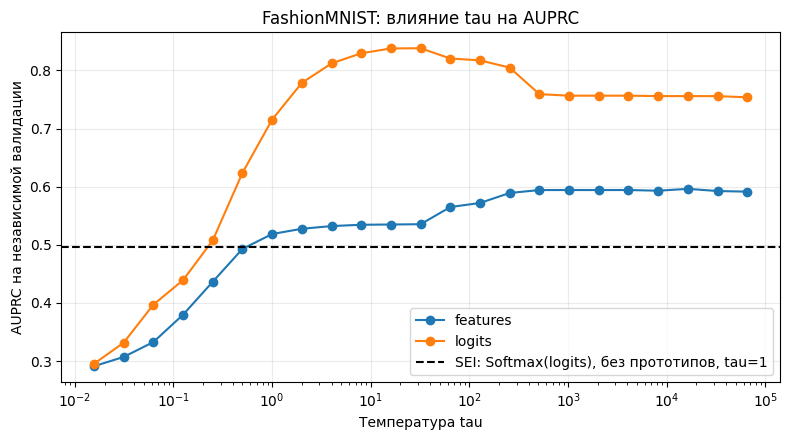

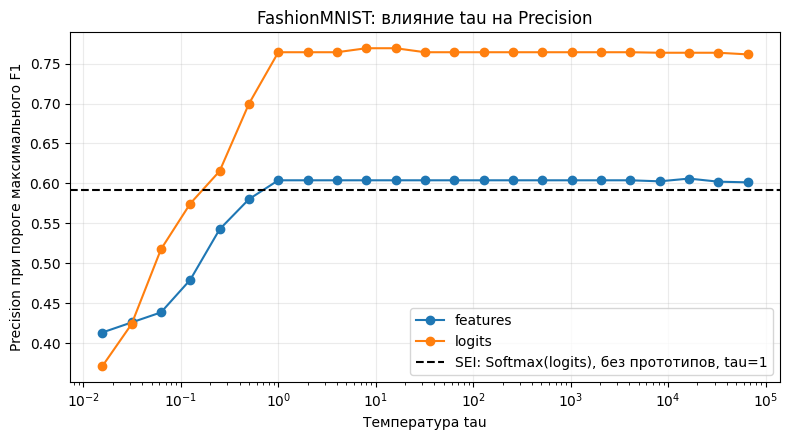

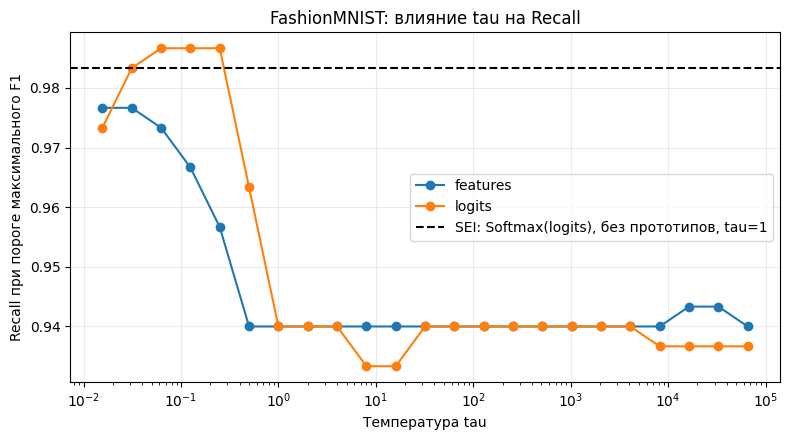

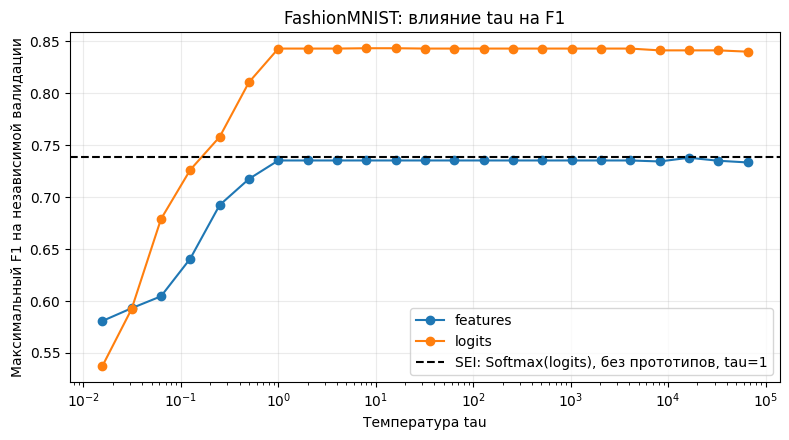

In [18]:
# 8.3 подбор tau на отделной выборке, 
# при этом не пересекается с X_train, 
# AUPRC обнаружения ошибок  
def load_val_subset(dataset_name, train_limit, val_limit):
    DatasetClass = datasets.MNIST if dataset_name.lower() == "mnist" else datasets.FashionMNIST
    data = DatasetClass(root=DATA_ROOT, train=True, download=True)

    if train_limit is None:
        raise ValueError("Для отдельной валидации выборки задайте TRAIN_LIMIT")

    generator = torch.Generator().manual_seed(SEED)
    perm = torch.randperm(len(data.targets), generator=generator)
    val_start = train_limit
    val_end = val_start + val_limit
    if val_end > len(data.targets):
        raise ValueError("TRAIN_LIMIT + VAL_LIMIT превышает размер исходной обучающей выборки")

    ids = perm[val_start:val_end]
    X = data.data[ids].float().unsqueeze(1) / 255.0
    y = torch.as_tensor(data.targets, dtype=torch.long)[ids]
    return X, y


def best_f1_operating_point(y_true_binary, score):
    """Возвращает Precision, Recall, F1 в точке порога, максимизирующей F1 на валидации"""
    
    precision, recall, thresholds = precision_recall_curve(y_true_binary, score)
    f1_values = 2.0 * precision * recall / np.maximum(precision + recall, EPS)
  
    best_idx = int(np.nanargmax(f1_values))
    threshold = thresholds[best_idx] if best_idx < len(thresholds) else np.inf
  
    return {
        "Precision": float(precision[best_idx]),
        "Recall": float(recall[best_idx]),
        "F1": float(f1_values[best_idx]),
        "F1 threshold": float(threshold),
    }


def tune_tau(X_fit, y_fit_clean, X_val, y_val_clean, noise_rate=VAL_NOISE_RATE):
    rows = []
    reference_rows = []
    num_classes_local = int(max(y_fit_clean.max().item(), y_val_clean.max().item()) + 1)

    for tuning_seed in TAU_TUNING_SEEDS:
        print(f"Подбор tau для seed={tuning_seed}")

        y_fit_noisy, _ = make_noisy_labels(
            X_fit, y_fit_clean, "symmetric", noise_rate, seed=tuning_seed + 700
        )

        y_val_noisy, val_mask = make_noisy_labels(
            X_val, y_val_clean, "symmetric", noise_rate, seed=tuning_seed + 1700
        )

        y_val_np = y_val_noisy.numpy()
        val_mask_np = val_mask.astype(int)

        traj = train_with_trajectory(
            X_fit, y_fit_noisy, num_classes_local, epochs=SEI_EPOCHS,
            seed=tuning_seed + 2700, eval_X=X_val
        )

        # софтмакс от логитов, без прототипов
        #!!! в softmax_np(logits)  tau=1
        reference_probabilities = softmax_np(traj["logits"])
        reference_score = sei_score(reference_probabilities, y_val_np)
        reference_ap = average_precision_score(val_mask_np, reference_score)
        reference_point = best_f1_operating_point(val_mask_np, reference_score)
        reference_rows.append({"seed": tuning_seed, "AUPRC": reference_ap, **reference_point})

        for emb in ["features", "logits"]:
            fit_trajectory = traj[f"reference_{emb}"]
    
            for tau in TAU_GRID:
                probabilities = prototype_probs_external(
                    traj[emb], fit_trajectory, y_fit_noisy.numpy(), num_classes_local, tau
                )
    
                score = sei_score(probabilities, y_val_np)
                ap = average_precision_score(val_mask_np, score)
                prf = best_f1_operating_point(val_mask_np, score)
                rows.append({
                    "seed": tuning_seed, "emb": emb, "tau": tau,
                    "AUPRC": float(ap), **prf,
                })

    runs = pd.DataFrame(rows)
    tuning_df = (runs.groupby(["emb", "tau"], as_index=False)
                 [["AUPRC", "Precision", "Recall", "F1", "F1 threshold"]].mean())
    best_rows = tuning_df.loc[tuning_df.groupby("emb")["AUPRC"].idxmax()]
    tau_by_embedding = {row.emb: float(row.tau) for row in best_rows.itertuples()}
    
    best_tau = {
        (emb, loo): tau_by_embedding[emb]
        for emb in ["features", "logits"]
        for loo in [False, True]
    }

    reference_runs = pd.DataFrame(reference_rows)
    reference_metrics = reference_runs[["AUPRC", "Precision", "Recall", "F1"]].mean().to_dict()

    return tuning_df, best_tau, reference_metrics, runs, reference_runs


X_val, y_val_clean = load_val_subset(DATASET_NAME, TRAIN_LIMIT, VAL_LIMIT)
tuning_df, best_tau, reference_metrics, tau_tuning_runs, tau_reference_runs = tune_tau(
    X_train, y_true, X_val, y_val_clean
)

print("Базовый SEI: Softmax(logits), без прототипов, tau=1:")
print({k: round(v, 4) for k, v in reference_metrics.items()})
print("Оптимальные tau по AUPRC:", best_tau)
display(tuning_df.round(4))

#4 отдельных графика: ранжирование и P/R/F1 в точке максимального F1
metric_plots = [
    ("AUPRC", "AUPRC на независимой валидации"),
    ("Precision", "Precision при пороге максимального F1"),
    ("Recall", "Recall при пороге максимального F1"),
    ("F1", "Максимальный F1 на независимой валидации"),
]

for metric, y_label in metric_plots:
    plt.figure(figsize=(8, 4.5))
    for emb, group in tuning_df.groupby("emb"):
        group = group.sort_values("tau")
        plt.plot(group["tau"], group[metric], marker="o", label=emb)

    plt.axhline(
        reference_metrics[metric], color="black", linestyle="--",
        label="SEI: Softmax(logits), без прототипов, tau=1"
    )
    
    plt.xscale("log")
    plt.xlabel("Температура tau")
    plt.ylabel(y_label)
    plt.title(f"{DATASET_NAME}: влияние tau на {metric}")
    plt.legend()
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, f"tau_validation_{metric.lower()}.png"), dpi=180)
    plt.show()

tuning_df.to_csv(os.path.join(OUTPUT_DIR, "results_tau_tuning.csv"), index=False)
tau_tuning_runs.to_csv(os.path.join(OUTPUT_DIR, "results_tau_tuning_runs.csv"), index=False)
tau_reference_runs.to_csv(os.path.join(OUTPUT_DIR, "results_tau_reference_metrics.csv"), index=False)


Базовый SEI использует Softmax непосредственно от logits с температурой 1. В прототипном SEI сначала вычисляются косинусные сходства изображения с прототипами классов, после чего применяется Softmax с подобранной температурой tau.

## Этап 8.4. Сравнение вариантов SEI на искусственном шуме

In [26]:
# 8.4 СРАВНЕНИЕ: SEI, SEI на прототипах и Cleanlab
# tau из 8.3
replicate_cache = {}
auxiliary_threshold_rows = []
auxiliary_diagnostics = {}


def get_cleanlab_oof_probabilities(
    X, y_observed, num_classes=NUM_CLASSES, folds=FOLDS,
    epochs=OOF_EPOCHS, seed=SEED,
):
    """Получает OOF-вероятности: каждый объект оценивается моделью,
    которая не обучалась на этом объекте.

    Функция предназначена только для Cleanlab; дополнительные сигналы
    Dynamics/KNN/Ensemble не вычисляются.
    """
    labels = y_observed.detach().cpu().numpy()
    class_counts = np.bincount(labels, minlength=num_classes)
    present_counts = class_counts[class_counts > 0]
    if len(present_counts) < num_classes:
        raise ValueError(
            "В зашумлённой обучающей выборке отсутствует один или несколько классов."
        )
    if present_counts.min() < folds:
        raise ValueError(
            f"Для StratifiedKFold с folds={folds} нужно не менее {folds} "
            "объектов каждого класса."
        )

    splitter = StratifiedKFold(
        n_splits=folds, shuffle=True, random_state=seed
    )
    oof_probs = np.zeros((len(labels), num_classes), dtype=np.float32)

    for fold, (train_ids, valid_ids) in enumerate(
        splitter.split(np.zeros(len(labels)), labels)
    ):
        print(f"Cleanlab OOF: фолд {fold + 1}/{folds}")
        set_seed(seed + fold)
        model = SimpleCNN(
            in_channels=X.shape[1], num_classes=num_classes
        ).to(DEVICE)
        optimizer = torch.optim.Adam(model.parameters(), lr=SEI_LR)
        train_loader = DataLoader(
            TensorDataset(X[train_ids], y_observed[train_ids]),
            batch_size=BATCH_SIZE,
            shuffle=True,
            pin_memory=(DEVICE.type == "cuda"),
        )

        for epoch in range(epochs):
            train_one_epoch(model, train_loader, optimizer)

        fold_probs, _ = predict(model, X[valid_ids], batch_size=BATCH_SIZE)
        oof_probs[valid_ids] = fold_probs

        del model, optimizer, train_loader
        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()

    if not np.allclose(oof_probs.sum(axis=1), 1.0, atol=1e-4):
        raise RuntimeError("Не удалось получить корректные OOF-вероятности для всех объектов.")

    return oof_probs


def run_one(X_tr, y_tr_clean, noise_type, rate, seed):
    y_noisy_l, mask = make_noisy_labels(
        X_tr, y_tr_clean, noise_type, rate, seed=seed
    )
    mask_i = mask.astype(int)
    y_np = y_noisy_l.numpy()

    traj = train_with_trajectory(
        X_tr, y_noisy_l, NUM_CLASSES, SEI_EPOCHS, seed=seed
    )
    scores = compute_sei_scores(traj, y_np, best_tau)

    if RUN_AUXILIARY_CLASS:
        anchor_mask = make_auxiliary_anchor_mask(
            n_samples=len(y_noisy_l), num_classes=NUM_CLASSES,
            seed=seed + AUX_SEED_OFFSET,
        )
        for emb in ["features", "logits"]:
            tau_aux = best_tau[(emb, False)]
            for loo_aux in AUX_LOO_OPTIONS:
                aux_result = auxiliary_class_sei(
                    traj[emb], y_np, NUM_CLASSES, tau_aux, anchor_mask, loo=loo_aux
                )
                method_name = f"Auxiliary Class [{emb}{', LOO' if loo_aux else ''}]"
                scores[method_name] = aux_result["suspicion_score"]

                threshold_metrics = evaluate_auxiliary_threshold(mask_i, aux_result)
                auxiliary_threshold_rows.append({
                    "Датасет": DATASET_NAME,
                    "noise_type": noise_type,
                    "noise_rate": rate,
                    "seed": seed,
                    "Представление": emb,
                    "LOO": loo_aux,
                    "tau": tau_aux,
                    **threshold_metrics,
                })

                # Сохраняем распределение только для основного запуска и LOO=True.
                if (noise_type == NOISE_TYPE and rate == NOISE_RATE
                        and seed == EVAL_SEEDS[0] and loo_aux):
                    auxiliary_diagnostics[emb] = {
                        "result": aux_result,
                        "noise_mask": mask_i.copy(),
                    }

    cache_entry = {
        "y_noisy": y_noisy_l.clone(),
        "noise_mask": mask_i.copy(),
        "sei_scores": scores,
    }

    if RUN_CLEANLAB_8_4:
        # Cleanlab получает только OOF-прогнозы: объект не входит в обучение
        # модели, которая формирует для него вероятности.
        oof_probs = get_cleanlab_oof_probabilities(
            X_tr, y_noisy_l,
            num_classes=NUM_CLASSES,
            folds=FOLDS,
            epochs=OOF_EPOCHS,
            seed=seed,
        )
        label_quality = get_label_quality_scores(
            labels=y_np,
            pred_probs=oof_probs,
        )
        cleanlab_score = 1.0 - np.asarray(label_quality, dtype=float)
        scores["Cleanlab"] = cleanlab_score
        cache_entry["oof_probs"] = oof_probs
        cache_entry["cleanlab_score"] = cleanlab_score

    replicate_cache[seed] = cache_entry

    return [
        dict(evaluate_score(name, score, mask_i),
             noise_type=noise_type, rate=rate, seed=seed)
        for name, score in scores.items()
    ]


all_rows = []
for noise_type in EVAL_NOISE_TYPES:
    for rate in EVAL_NOISE_RATES:
        for seed in EVAL_SEEDS:
            print(f"--- {noise_type}, шум {rate:.0%}, seed {seed}")
            all_rows += run_one(X_train, y_true, noise_type, rate, seed)

sei_results = pd.DataFrame(all_rows)
sei_results.to_csv(os.path.join(OUTPUT_DIR, "results_sei_detection.csv"), index=False)

summary = (sei_results.groupby(["noise_type", "rate", "Метод"], as_index=False)
           [["Precision@K", "Average Precision", "ROC-AUC"]].mean())

print("Результаты обнаружения ошибок для seed=42:")
display(summary.sort_values("Average Precision", ascending=False).round(3))


--- symmetric, шум 10%, seed 123
Cleanlab OOF: фолд 1/3
Cleanlab OOF: фолд 2/3
Cleanlab OOF: фолд 3/3
Результаты обнаружения ошибок для seed=42:


,noise_type,rate,Метод,Precision@K,Average Precision,ROC-AUC
4,symmetric,0.1,Cleanlab,0.906,0.950,0.994
11,symmetric,0.1,"SEI прототипы [logits, LOO]",0.879,0.891,0.990
12,symmetric,0.1,SEI прототипы [logits],0.879,0.891,0.990
10,symmetric,0.1,SEI прототипы [features],0.633,0.626,0.963
9,symmetric,0.1,"SEI прототипы [features, LOO]",0.637,0.626,0.963
8,symmetric,0.1,SEI (softmax логитов),0.622,0.607,0.960
3,symmetric,0.1,Auxiliary Class [logits],0.514,0.520,0.944
2,symmetric,0.1,"Auxiliary Class [logits, LOO]",0.514,0.520,0.944
6,symmetric,0.1,SE@last (softmax),0.525,0.502,0.932
7,symmetric,0.1,SE@middle (softmax),0.383,0.420,0.924


## Этап 8.5 Auxiliary Class



In [12]:
# 8.5 Запуск Auxiliary Class Threshold на основной выборке
if RUN_AUXILIARY_CLASS:
    if not auxiliary_threshold_rows:
        print("Auxiliary Class не запускался: проверьте EVAL_SEEDS / этап 8.4")
    else:
        auxiliary_threshold_df = pd.DataFrame(auxiliary_threshold_rows)
        display(auxiliary_threshold_df.round(4))
        auxiliary_threshold_df.to_csv(
            os.path.join(OUTPUT_DIR, "results_auxiliary_threshold_fashion.csv"), index=False
        )

else:
    print("Auxiliary Class отключён: RUN_AUXILIARY_CLASS=False")


,Датасет,noise_type,noise_rate,seed,Представление,LOO,tau,Precision,Recall,F1,AUPRC,ROC-AUC,Threshold (SEI),Auxiliary count,Flagged count,Flagged fraction,TP,FP,FN,TN
0,FashionMNIST,symmetric,0.4,42,features,False,128.0,0.8168,0.9472,0.8772,0.7979,0.9166,-239.7546,4545,23195,0.4639,18945,4250,1055,25750
1,FashionMNIST,symmetric,0.4,42,features,True,128.0,0.8166,0.9474,0.8772,0.7978,0.9165,-239.7546,4545,23205,0.4641,18949,4256,1051,25744
2,FashionMNIST,symmetric,0.4,42,logits,False,32.0,0.8507,0.9079,0.8784,0.8546,0.9403,-239.4048,4545,21344,0.4269,18158,3186,1842,26814
3,FashionMNIST,symmetric,0.4,42,logits,True,32.0,0.8507,0.9082,0.8785,0.8545,0.9403,-239.4122,4545,21353,0.4271,18164,3189,1836,26811


## Этап 8.6. CIFAR-10: проверка CNN, SEI, Cleanlab и порога по F1

Используется стандартный CIFAR-10 с исходными чистыми метками. Для контролируемого эксперимента симметричный шум независимо создаётся на обучающей, валидационной и тестовой выборках.

1. Проверяется качество базовой SimpleCNN, обученной на чистых метках.
2. Обучается такая же CNN на искусственно зашумлённых обучающих метках; её классификационное качество оценивается на чистом тесте.
3. Сравниваются базовый SEI (Softmax от logits), прототипный SEI в пространствах features/logits и Cleanlab.
4. Для Cleanlab используются вероятности последней эпохи той же CNN. Validation и test не участвуют в обучении CNN, поэтому вероятности для этих объектов являются out-of-sample.
5. Температура прототипного SEI выбирается по AUPRC на validation. Порог подозрительности каждого метода, включая Cleanlab, выбирается по максимальному F1 на validation.
6. Выбранные tau и пороги без изменений применяются к отдельной тестовой выборке. Тестовая маска используется только для итоговой оценки.

Результаты сохраняются в отдельных таблицах: сравнение на validation, сравнение на test и таблица выбранных порогов.

### Сравнение с Cleanlab

Cleanlab оценивается на тех же validation и test объектах, что и SEI. Для него используются вероятности Softmax последней эпохи CNN, обученной только на зашумлённой обучающей выборке. Поэтому validation и test являются out-of-sample относительно этой CNN. Функция Cleanlab возвращает оценку качества текущей метки (чем выше, тем метка надёжнее); для сопоставления с SEI она преобразуется в рейтинг подозрительности `1 - label_quality`. Порог Cleanlab, как и пороги SEI, выбирается по максимальному F1 на validation и без изменений применяется к test.

Размеры CIFAR-10: train=45000, validation=5000, test=10000
Clean CNN: эпоха 10/100
Clean CNN: эпоха 20/100
Clean CNN: эпоха 30/100
Clean CNN: эпоха 40/100
Clean CNN: эпоха 50/100
Clean CNN: эпоха 60/100
Clean CNN: эпоха 70/100
Clean CNN: эпоха 80/100
Clean CNN: эпоха 90/100
Clean CNN: эпоха 100/100
Качество базовой CNN на чистом тесте CIFAR-10:


,Модель,Accuracy,Macro-F1
0,"SimpleCNN, обучение на чистых метках",0.7060,0.7050
1,"SimpleCNN, обучение на noisy-метках",0.6863,0.6842


Сравнение SEI и Cleanlab на validation (порог выбран по F1):


,Метод,Precision@K,Average Precision,ROC-AUC,Precision,Recall,F1,Threshold selected on validation,Flagged count,Flagged fraction,TP,FP,FN,TN,tau
0,"SEI (Softmax logits), без прототипов",0.262,0.2666,0.8346,0.2644,0.908,0.4096,41.8921,1717,0.3434,454,1263,46,3237,1.0
1,Cleanlab,0.662,0.7246,0.9401,0.7042,0.638,0.6695,0.9797,453,0.0906,319,134,181,4366,NaN
2,SEI prototypes [features],0.360,0.3416,0.8751,0.3589,0.832,0.5015,230.2583,1159,0.2318,416,743,84,3757,65536.0
3,SEI prototypes [logits],0.446,0.4083,0.9043,0.4311,0.820,0.5651,230.2583,951,0.1902,410,541,90,3959,65536.0


Сравнение SEI и Cleanlab на тестовой выборке CIFAR-10 (порог выбран по F1 на validation):


,Метод,Precision@K,Average Precision,ROC-AUC,Precision,Recall,F1,Threshold selected on validation,Flagged count,Flagged fraction,TP,FP,FN,TN,tau,Validation AUPRC,Validation F1
0,"SEI (Softmax logits), без прототипов",0.241,0.2508,0.8299,0.2653,0.895,0.4092,41.8921,3374,0.3374,895,2479,105,6521,1.0,0.2666,0.4096
1,Cleanlab,0.686,0.7392,0.9455,0.7286,0.631,0.6763,0.9797,866,0.0866,631,235,369,8765,NaN,0.7246,0.6695
2,SEI prototypes [features],0.359,0.3618,0.8860,0.3787,0.841,0.5222,230.2583,2221,0.2221,841,1380,159,7620,65536.0,0.3416,0.5015
3,SEI prototypes [logits],0.462,0.4317,0.9108,0.4560,0.818,0.5855,230.2583,1794,0.1794,818,976,182,8024,65536.0,0.4083,0.5651


Выбранные tau и пороги на валидационной выборке:


,Метод,tau,Validation AUPRC,Validation Precision,Validation Recall,Validation F1,Validation threshold
0,"SEI (Softmax logits), без прототипов",1.0,0.2666,0.2644,0.908,0.4096,41.8921
1,Cleanlab,NaN,0.7246,0.7042,0.638,0.6695,0.9797
2,SEI prototypes [features],65536.0,0.3416,0.3589,0.832,0.5015,230.2583
3,SEI prototypes [logits],65536.0,0.4083,0.4311,0.820,0.5651,230.2583


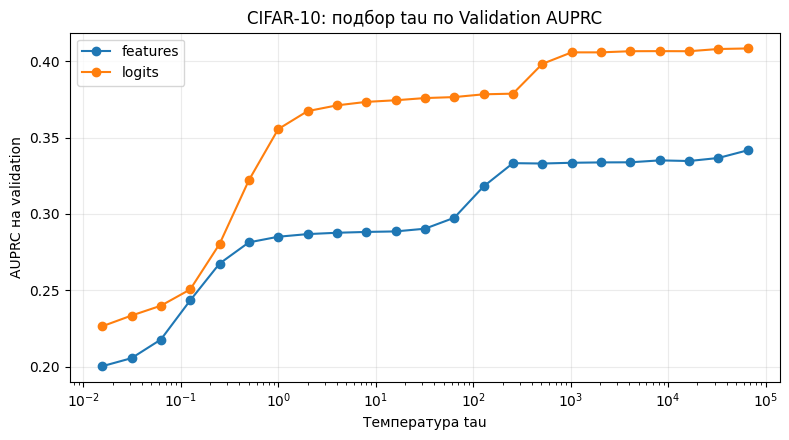

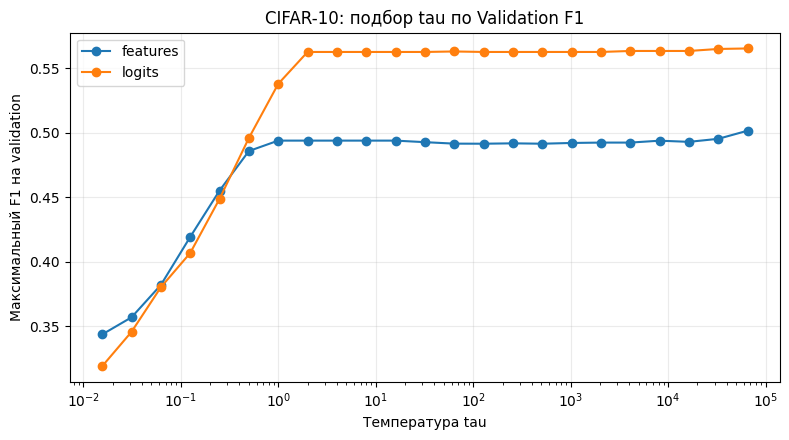

Эксперимент CIFAR-10 завершён. Результаты сохранены в: c:\Users\aptem\OneDrive\Desktop\политех\лабы\ВКР\results_vkr


In [27]:
if RUN_SEI_CIFAR10:
    cifar = load_cifar10_splits(
        data_root=DATA_ROOT,
        train_limit=CIFAR10_TRAIN_LIMIT,
        val_limit=CIFAR10_VAL_LIMIT,
        test_limit=CIFAR10_TEST_LIMIT,
        seed=SEED,
    )

    X_cifar_train = cifar["X_train"]
    y_cifar_train_clean = cifar["y_train_clean"]
    X_cifar_val = cifar["X_val"]
    y_cifar_val_clean = cifar["y_val_clean"]
    X_cifar_test = cifar["X_test"]
    y_cifar_test_clean = cifar["y_test_clean"]

    print(
        "Размеры CIFAR-10:",
        f"train={len(y_cifar_train_clean)},",
        f"validation={len(y_cifar_val_clean)},",
        f"test={len(y_cifar_test_clean)}",
    )

    # Независимо портим метки в train, validation, test
    # Исходные чистые метки сохраняются для обучения контрольной CNN и оценки.
    y_cifar_train_noisy, cifar_train_noise_mask = make_noisy_labels(
        X_cifar_train, y_cifar_train_clean,
        CIFAR10_NOISE_TYPE, CIFAR10_NOISE_RATE,
        seed=SEED + CIFAR10_SEED_OFFSET + 1,
    )
    y_cifar_val_noisy, cifar_val_noise_mask = make_noisy_labels(
        X_cifar_val, y_cifar_val_clean,
        CIFAR10_NOISE_TYPE, CIFAR10_NOISE_RATE,
        seed=SEED + CIFAR10_SEED_OFFSET + 2,
    )
    y_cifar_test_noisy, cifar_test_noise_mask = make_noisy_labels(
        X_cifar_test, y_cifar_test_clean,
        CIFAR10_NOISE_TYPE, CIFAR10_NOISE_RATE,
        seed=SEED + CIFAR10_SEED_OFFSET + 3,
    )

    cifar_train_mask_np = cifar_train_noise_mask.astype(int)
    cifar_val_mask_np = cifar_val_noise_mask.astype(int)
    cifar_test_mask_np = cifar_test_noise_mask.astype(int)
    y_cifar_train_noisy_np = y_cifar_train_noisy.numpy()
    y_cifar_val_noisy_np = y_cifar_val_noisy.numpy()
    y_cifar_test_noisy_np = y_cifar_test_noisy.numpy()
    y_cifar_test_clean_np = y_cifar_test_clean.numpy()

    #Контроль качества базовой CNN, обученной на ЧИСТЫХ метках
    def train_clean_cnn_baseline(
        X_train, y_train, X_test, y_test, epochs, seed
    ):
        set_seed(seed)
        model = SimpleCNN(
            in_channels=X_train.shape[1], num_classes=10
        ).to(DEVICE)
        optimizer = torch.optim.Adam(model.parameters(), lr=SEI_LR)
        loader = DataLoader(
            TensorDataset(X_train, y_train),
            batch_size=BATCH_SIZE,
            shuffle=True,
            pin_memory=(DEVICE.type == "cuda"),
        )

        for epoch in range(epochs):
            train_one_epoch(model, loader, optimizer)
            if (epoch + 1) % 10 == 0 or epoch + 1 == epochs:
                print(f"Clean CNN: эпоха {epoch + 1}/{epochs}")

        test_logits, _ = predict_logits(model, X_test)
        predictions = test_logits.argmax(axis=1)
        y_true_np = y_test.numpy()

        return {
            "Модель": "SimpleCNN, обучение на чистых метках",
            "Accuracy": float(accuracy_score(y_true_np, predictions)),
            "Macro-F1": float(f1_score(
                y_true_np, predictions, average="macro", zero_division=0
            )),
        }

    cnn_quality_rows = []

    if CIFAR10_RUN_CLEAN_CNN_BASELINE:
        clean_cnn_row = train_clean_cnn_baseline(
            X_cifar_train, y_cifar_train_clean,
            X_cifar_test, y_cifar_test_clean,
            epochs=CIFAR10_EPOCHS,
            seed=SEED + CIFAR10_SEED_OFFSET + 100,
        )
        cnn_quality_rows.append(clean_cnn_row)

    #CNN обучается на зашумлённых train-метках.
    #За 1 проход сохраняем траектории validation + test и
    #отдельно reference-представления обучающих изображений
    X_cifar_eval = torch.cat([X_cifar_val, X_cifar_test], dim=0)
    n_cifar_val = len(y_cifar_val_clean)

    cifar_traj = train_with_trajectory(
        X_cifar_train,
        y_cifar_train_noisy,
        num_classes=10,
        epochs=CIFAR10_EPOCHS,
        seed=SEED + CIFAR10_SEED_OFFSET + 200,
        eval_X=X_cifar_eval,
    )

    # Качество этой же CNN-классификации проверяем по чистым тестовым меткам.
    cifar_test_logits_noisy_cnn = cifar_traj["logits"][-1, n_cifar_val:, :]
    cifar_test_pred_noisy_cnn = cifar_test_logits_noisy_cnn.argmax(axis=1)
    cnn_quality_rows.append({
        "Модель": "SimpleCNN, обучение на noisy-метках",
        "Accuracy": float(accuracy_score(
            y_cifar_test_clean_np, cifar_test_pred_noisy_cnn
        )),
        "Macro-F1": float(f1_score(
            y_cifar_test_clean_np, cifar_test_pred_noisy_cnn,
            average="macro", zero_division=0
        )),
    })

    cnn_quality_df = pd.DataFrame(cnn_quality_rows)
    print("Качество базовой CNN на чистом тесте CIFAR-10:")
    display(cnn_quality_df.round(4))
    cnn_quality_df.to_csv(
        os.path.join(OUTPUT_DIR, "results_cifar10_cnn_quality.csv"),
        index=False,
    )

    #Выбор tau и порога обнаружения только на валидации
    #Порог для каждого метода выбирается по максимальному F1.
    val_logits = cifar_traj["logits"][:, :n_cifar_val, :]
    test_logits = cifar_traj["logits"][:, n_cifar_val:, :]

    tau_rows = []
    selected_methods = {}
    validation_score_by_method = {}

    # Контрольный вариант: обычный SEI = Softmax(logits), tau=1, без прототипов
    P_val_base = softmax_np(val_logits)
    score_val_base = sei_score(P_val_base, y_cifar_val_noisy_np)
    base_val_ap = average_precision_score(cifar_val_mask_np, score_val_base)
    base_val_point = best_f1_operating_point(
        cifar_val_mask_np, score_val_base
    )
    base_method_name = "SEI (Softmax logits), без прототипов"
    validation_score_by_method[base_method_name] = score_val_base
    selected_methods[base_method_name] = {
        "tau": 1.0,
        "threshold": base_val_point["F1 threshold"],
        "validation_AUPRC": float(base_val_ap),
        "validation_Precision": base_val_point["Precision"],
        "validation_Recall": base_val_point["Recall"],
        "validation_F1": base_val_point["F1"],
    }

    # Cleanlab: вероятности последней эпохи той же CNN на независимой validation.
    # Модель обучалась только на X_cifar_train, поэтому validation не является
    # обучающей выборкой для этой модели. Cleanlab возвращает quality score:
    # высокое значение означает более надёжную метку. Для общей шкалы
    # подозрительности используем 1 - quality score.
    P_val_cleanlab = softmax_np(val_logits[-1])
    cleanlab_val_quality = get_label_quality_scores(
        labels=y_cifar_val_noisy_np,
        pred_probs=P_val_cleanlab,
    )
    cleanlab_val_score = 1.0 - np.asarray(cleanlab_val_quality, dtype=float)
    cleanlab_val_ap = float(average_precision_score(
        cifar_val_mask_np, cleanlab_val_score
    ))
    cleanlab_val_point = best_f1_operating_point(
        cifar_val_mask_np, cleanlab_val_score
    )
    cleanlab_name = "Cleanlab"
    validation_score_by_method[cleanlab_name] = cleanlab_val_score
    selected_methods[cleanlab_name] = {
        "tau": None,
        "threshold": cleanlab_val_point["F1 threshold"],
        "validation_AUPRC": cleanlab_val_ap,
        "validation_Precision": cleanlab_val_point["Precision"],
        "validation_Recall": cleanlab_val_point["Recall"],
        "validation_F1": cleanlab_val_point["F1"],
    }

    for emb in ["features", "logits"]:
        V_val = cifar_traj[emb][:, :n_cifar_val, :]
        V_test = cifar_traj[emb][:, n_cifar_val:, :]
        V_reference = cifar_traj[f"reference_{emb}"]

        best_row = None
        best_score_val = None
        for tau in TAU_GRID:
            P_val = prototype_probs_external(
                V_val,
                V_reference,
                y_cifar_train_noisy_np,
                num_classes=10,
                tau=tau,
            )
            score_val = sei_score(P_val, y_cifar_val_noisy_np)
            ap = float(average_precision_score(
                cifar_val_mask_np, score_val
            ))
            f1_point = best_f1_operating_point(
                cifar_val_mask_np, score_val
            )

            row = {
                "Представление": emb,
                "tau": float(tau),
                "Validation AUPRC": ap,
                "Validation Precision": f1_point["Precision"],
                "Validation Recall": f1_point["Recall"],
                "Validation F1": f1_point["F1"],
                "Validation threshold": f1_point["F1 threshold"],
            }
            tau_rows.append(row)

            if best_row is None or ap > best_row["Validation AUPRC"]:
                best_row = row
                best_score_val = score_val.copy()

        prototype_method_name = f"SEI prototypes [{emb}]"
        validation_score_by_method[prototype_method_name] = best_score_val
        selected_methods[prototype_method_name] = {
            "tau": best_row["tau"],
            "threshold": best_row["Validation threshold"],
            "validation_AUPRC": best_row["Validation AUPRC"],
            "validation_Precision": best_row["Validation Precision"],
            "validation_Recall": best_row["Validation Recall"],
            "validation_F1": best_row["Validation F1"],
        }

    cifar_tau_df = pd.DataFrame(tau_rows)
    cifar_tau_df.to_csv(
        os.path.join(OUTPUT_DIR, "results_cifar10_tau_validation.csv"),
        index=False,
    )

    #Независимая оценка на тесте с tau и порогами, уже выбранными
    #на валидации, порог на тесте не перенастраивается
    test_score_by_method = {}

    P_test_base = softmax_np(test_logits)
    test_score_by_method[base_method_name] = sei_score(
        P_test_base, y_cifar_test_noisy_np
    )

    # Cleanlab на независимом test: те же параметры CNN, последняя эпоха.
    P_test_cleanlab = softmax_np(test_logits[-1])
    cleanlab_test_quality = get_label_quality_scores(
        labels=y_cifar_test_noisy_np,
        pred_probs=P_test_cleanlab,
    )
    test_score_by_method[cleanlab_name] = 1.0 - np.asarray(
        cleanlab_test_quality, dtype=float
    )

    for emb in ["features", "logits"]:
        V_test = cifar_traj[emb][:, n_cifar_val:, :]
        V_reference = cifar_traj[f"reference_{emb}"]
        tau = selected_methods[f"SEI prototypes [{emb}]"]["tau"]

        P_test = prototype_probs_external(
            V_test,
            V_reference,
            y_cifar_train_noisy_np,
            num_classes=10,
            tau=tau,
        )
        test_score_by_method[f"SEI prototypes [{emb}]"] = sei_score(
            P_test, y_cifar_test_noisy_np
        )

    def fixed_threshold_metrics(y_true_binary, score, threshold):
        y_true_binary = np.asarray(y_true_binary, dtype=bool)
        score = np.asarray(score)
        y_pred_binary = score >= threshold

        tp = int(np.sum(y_true_binary & y_pred_binary))
        fp = int(np.sum(~y_true_binary & y_pred_binary))
        fn = int(np.sum(y_true_binary & ~y_pred_binary))
        tn = int(np.sum(~y_true_binary & ~y_pred_binary))
        precision = tp / (tp + fp) if tp + fp else 0.0
        recall = tp / (tp + fn) if tp + fn else 0.0
        f1_value = (
            2 * precision * recall / (precision + recall)
            if precision + recall else 0.0
        )
        return {
            "Precision": precision,
            "Recall": recall,
            "F1": f1_value,
            "Threshold selected on validation": float(threshold),
            "Flagged count": int(y_pred_binary.sum()),
            "Flagged fraction": float(y_pred_binary.mean()),
            "TP": tp, "FP": fp, "FN": fn, "TN": tn,
        }

    # Сводная таблица validation: здесь выбирались tau и порог F1.
    cifar_validation_rows = []
    for method_name, score_val in validation_score_by_method.items():
        validation_ranking = evaluate_score(
            method_name, score_val, cifar_val_mask_np
        )
        validation_threshold_metrics = fixed_threshold_metrics(
            cifar_val_mask_np,
            score_val,
            selected_methods[method_name]["threshold"],
        )
        cifar_validation_rows.append({
            **validation_ranking,
            **validation_threshold_metrics,
            "tau": selected_methods[method_name]["tau"],
        })

    cifar_validation_df = pd.DataFrame(cifar_validation_rows)
    print("Сравнение SEI и Cleanlab на validation (порог выбран по F1):")
    display(cifar_validation_df.round(4))
    cifar_validation_df.to_csv(
        os.path.join(OUTPUT_DIR, "results_cifar10_validation_comparison.csv"),
        index=False,
    )

    cifar_detection_rows = []
    for method_name, score_test in test_score_by_method.items():
        threshold = selected_methods[method_name]["threshold"]
        ranking_metrics = evaluate_score(
            method_name, score_test, cifar_test_mask_np
        )
        threshold_metrics = fixed_threshold_metrics(
            cifar_test_mask_np, score_test, threshold
        )
        cifar_detection_rows.append({
            **ranking_metrics,
            **threshold_metrics,
            "tau": selected_methods[method_name]["tau"],
            "Validation AUPRC": selected_methods[method_name]["validation_AUPRC"],
            "Validation F1": selected_methods[method_name]["validation_F1"],
        })

    cifar_detection_df = pd.DataFrame(cifar_detection_rows)
    print(
        "Сравнение SEI и Cleanlab на тестовой выборке CIFAR-10 "
        "(порог выбран по F1 на validation):"
    )
    display(cifar_detection_df.round(4))
    # Сохраняем под общим именем; прежнее имя оставляем как совместимый alias.
    cifar_detection_df.to_csv(
        os.path.join(OUTPUT_DIR, "results_cifar10_detection_comparison.csv"),
        index=False,
    )
    cifar_detection_df.to_csv(
        os.path.join(OUTPUT_DIR, "results_cifar10_sei_detection.csv"),
        index=False,
    )

    cifar_selected_thresholds_df = pd.DataFrame([
        {
            "Метод": name,
            "tau": values["tau"],
            "Validation AUPRC": values["validation_AUPRC"],
            "Validation Precision": values["validation_Precision"],
            "Validation Recall": values["validation_Recall"],
            "Validation F1": values["validation_F1"],
            "Validation threshold": values["threshold"],
        }
        for name, values in selected_methods.items()
    ])
    print("Выбранные tau и пороги на валидационной выборке:")
    display(cifar_selected_thresholds_df.round(4))
    cifar_selected_thresholds_df.to_csv(
        os.path.join(OUTPUT_DIR, "results_cifar10_selected_thresholds.csv"),
        index=False,
    )

    # Графики подбора tau на валидации
    for metric, ylabel in [
        ("Validation AUPRC", "AUPRC на validation"),
        ("Validation F1", "Максимальный F1 на validation"),
    ]:
        plt.figure(figsize=(8, 4.5))
        for emb, group in cifar_tau_df.groupby("Представление"):
            group = group.sort_values("tau")
            plt.plot(group["tau"], group[metric], marker="o", label=emb)
        plt.xscale("log")
        plt.xlabel("Температура tau")
        plt.ylabel(ylabel)
        plt.title(f"CIFAR-10: подбор tau по {metric}")
        plt.grid(alpha=0.25)
        plt.legend()
        plt.tight_layout()
        plt.savefig(
            os.path.join(
                OUTPUT_DIR,
                f"cifar10_tau_{metric.lower().replace(' ', '_')}.png",
            ),
            dpi=180,
        )
        plt.show()

    print("Эксперимент CIFAR-10 завершён. Результаты сохранены в:", OUTPUT_DIR)

else:
    print("Эксперимент CIFAR-10 отключён: RUN_SEI_CIFAR10=False")
